<a href="https://colab.research.google.com/github/ReyAndrey22/Machine-Learning-Laboratories/blob/main/Laborator_2_%C3%8Env%C4%83%C8%9Bare_automat%C4%83.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Decision Trees

In [ ]:
#Import the libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn import tree
from pandas.core.common import random_state
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [ ]:
#Load the dataset
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Laboratoare_Învățare_automată/Lab2/gym_members_exercise_tracking.csv')
df.head(10)

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,Female,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71
3,25,Male,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,Male,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39
5,56,Female,58.0,1.68,168,156,74,1.59,1116.0,HIIT,15.5,2.7,5,3,20.55
6,36,Male,70.3,1.72,174,169,73,1.49,1385.0,Cardio,21.3,2.3,3,2,23.76
7,40,Female,69.7,1.51,189,141,64,1.27,895.0,Cardio,30.6,1.9,3,2,30.57
8,28,Male,121.7,1.94,185,127,52,1.03,719.0,Strength,28.9,2.6,4,2,32.34
9,28,Male,101.8,1.84,169,136,64,1.08,808.0,Cardio,29.7,2.7,3,1,30.07


In [ ]:
#Info about dataset
print("Shape of the dataset: " + str(df.shape))
print("Workout_Type: " + str(df['Workout_Type'].unique()))
df.info()
df.describe()

Shape of the dataset: (973, 15)
Workout_Type: ['Yoga' 'HIIT' 'Cardio' 'Strength']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    object 
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Workout_Type                   973 non-null    object 
 10  Fat_Percentage                 973 non-null    float64
 11  Water_Intake (liters)       

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,973.000000,973.000000,973.00000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000
mean,38.683453,73.854676,1.72258,179.883864,143.766701,62.223022,1.256423,905.422405,24.976773,2.626619,3.321686,1.809866,24.912127
std,12.180928,21.207500,0.12772,11.525686,14.345101,7.327060,0.343033,272.641516,6.259419,0.600172,0.913047,0.739693,6.660879
min,18.000000,40.000000,1.50000,160.000000,120.000000,50.000000,0.500000,303.000000,10.000000,1.500000,2.000000,1.000000,12.320000
25%,28.000000,58.100000,1.62000,170.000000,131.000000,56.000000,1.040000,720.000000,21.300000,2.200000,3.000000,1.000000,20.110000
50%,40.000000,70.000000,1.71000,180.000000,143.000000,62.000000,1.260000,893.000000,26.200000,2.600000,3.000000,2.000000,24.160000
75%,49.000000,86.000000,1.80000,190.000000,156.000000,68.000000,1.460000,1076.000000,29.300000,3.100000,4.000000,2.000000,28.560000
max,59.000000,129.900000,2.00000,199.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,49.840000


In [ ]:
#Data Cleaning
print(df.isnull().sum())
print(df.duplicated().sum())

Age                              0
Gender                           0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Calories_Burned                  0
Workout_Type                     0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
Experience_Level                 0
BMI                              0
dtype: int64
0


#Data Visualisation

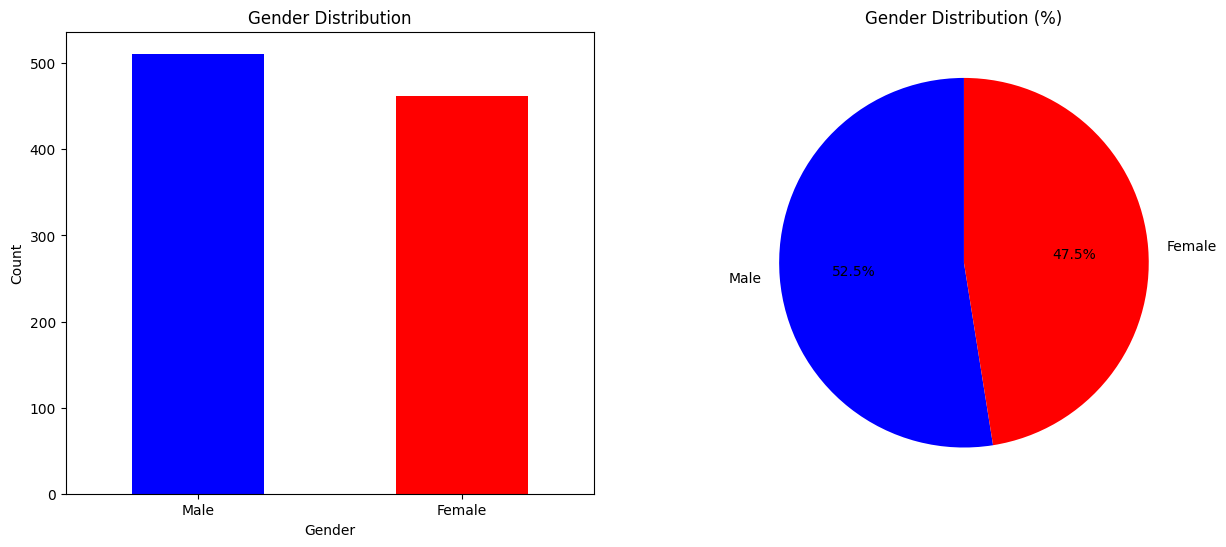

Gender distribution:
Gender
Male      511
Female    462
Name: count, dtype: int64



In [ ]:

gender_counts = df['Gender'].value_counts()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
gender_counts.plot(kind='bar', ax=ax1, color=['blue', 'red'])
ax1.set_title('Gender Distribution')
ax1.set_xlabel('Gender')
ax1.set_ylabel('Count')
ax1.tick_params(axis='x', rotation=0)
ax2.pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%', colors=['blue', 'red'], startangle=90)
ax2.set_title('Gender Distribution (%)')
plt.show()
print(f"Gender distribution:\n{gender_counts}\n")

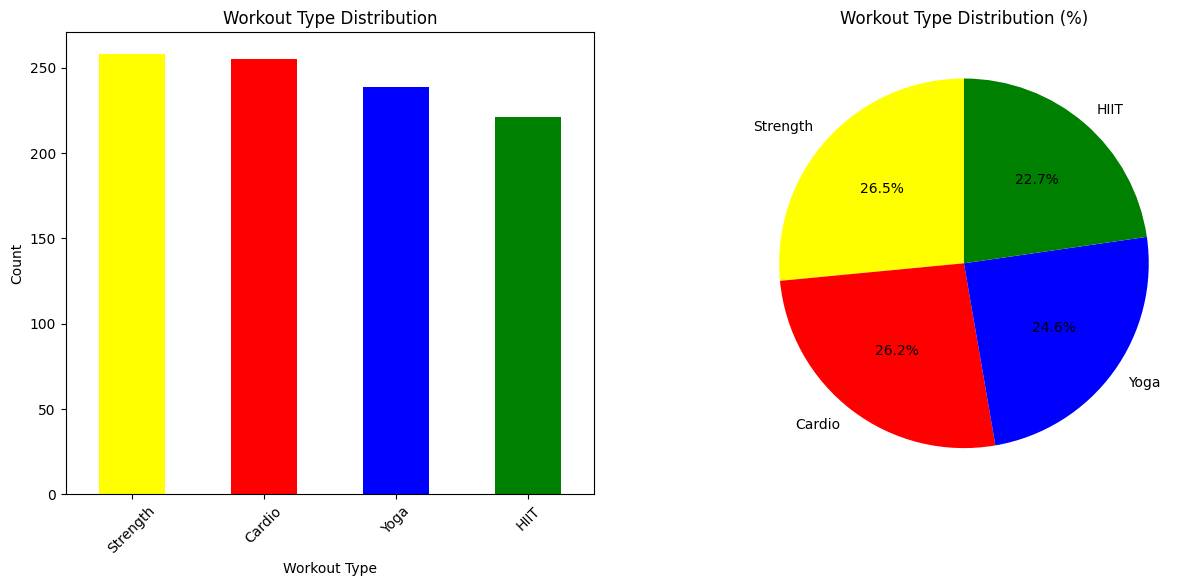

Workout type distribution:
Workout_Type
Strength    258
Cardio      255
Yoga        239
HIIT        221
Name: count, dtype: int64


In [ ]:
workout_counts = df['Workout_Type'].value_counts()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
workout_counts.plot(kind='bar', ax=ax1, color=['yellow', 'red', 'blue', 'green'])
ax1.set_title('Workout Type Distribution')
ax1.set_xlabel('Workout Type')
ax1.set_ylabel('Count')
ax1.tick_params(axis='x', rotation=45)
ax2.pie(workout_counts.values, labels=workout_counts.index, autopct='%1.1f%%', colors=['yellow', 'red', 'blue', 'green'], startangle=90)
ax2.set_title('Workout Type Distribution (%)')
plt.show()
print(f"Workout type distribution:\n{workout_counts}")

<Figure size 1000x600 with 0 Axes>

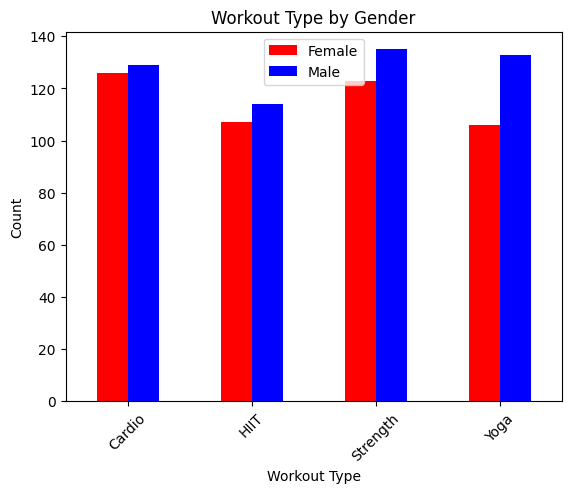

Workout type by gender:
Gender        Female  Male
Workout_Type              
Cardio           126   129
HIIT             107   114
Strength         123   135
Yoga             106   133


In [ ]:
plt.figure(figsize=(10, 6))
workout_gender = pd.crosstab(df['Workout_Type'], df['Gender'])
workout_gender.plot(kind='bar', color=['red', 'blue'])
plt.title('Workout Type by Gender')
plt.xlabel('Workout Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(loc='upper center')
plt.show()
print(f"Workout type by gender:\n{workout_gender}")


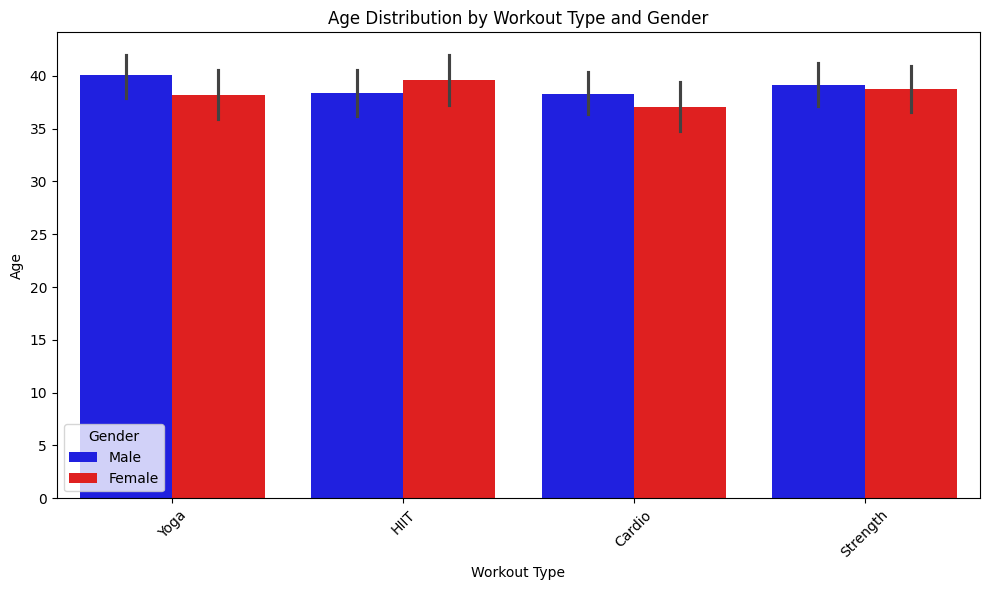

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Workout_Type', y='Age', hue='Gender', palette=['blue','red'], data=df)
plt.title('Age Distribution by Workout Type and Gender')
plt.xlabel('Workout Type')
plt.ylabel('Age')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

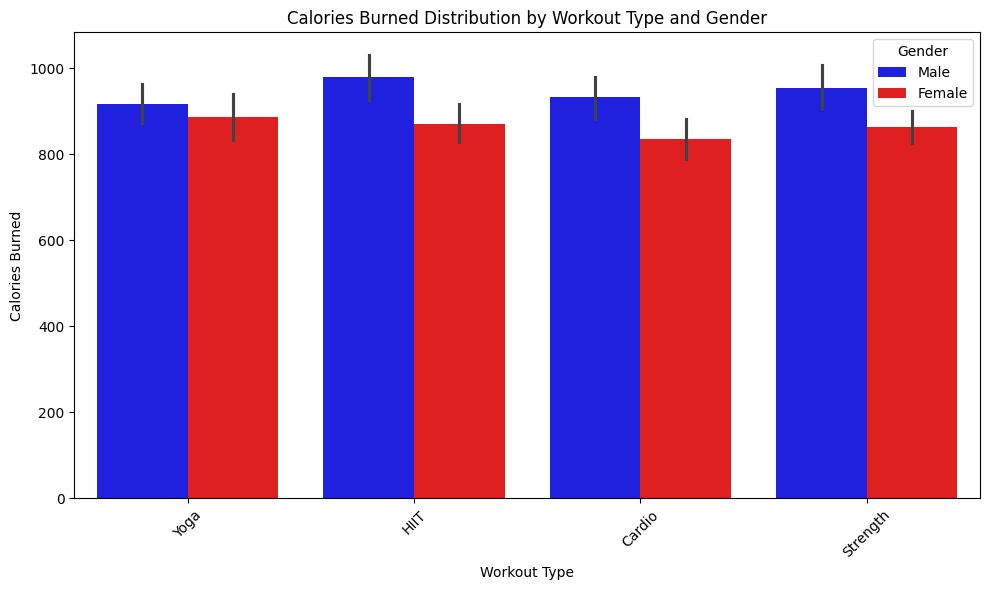

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Workout_Type', y='Calories_Burned', hue='Gender', palette=['blue','red'], data=df)
plt.title('Calories Burned Distribution by Workout Type and Gender')
plt.xlabel('Workout Type')
plt.ylabel('Calories Burned')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

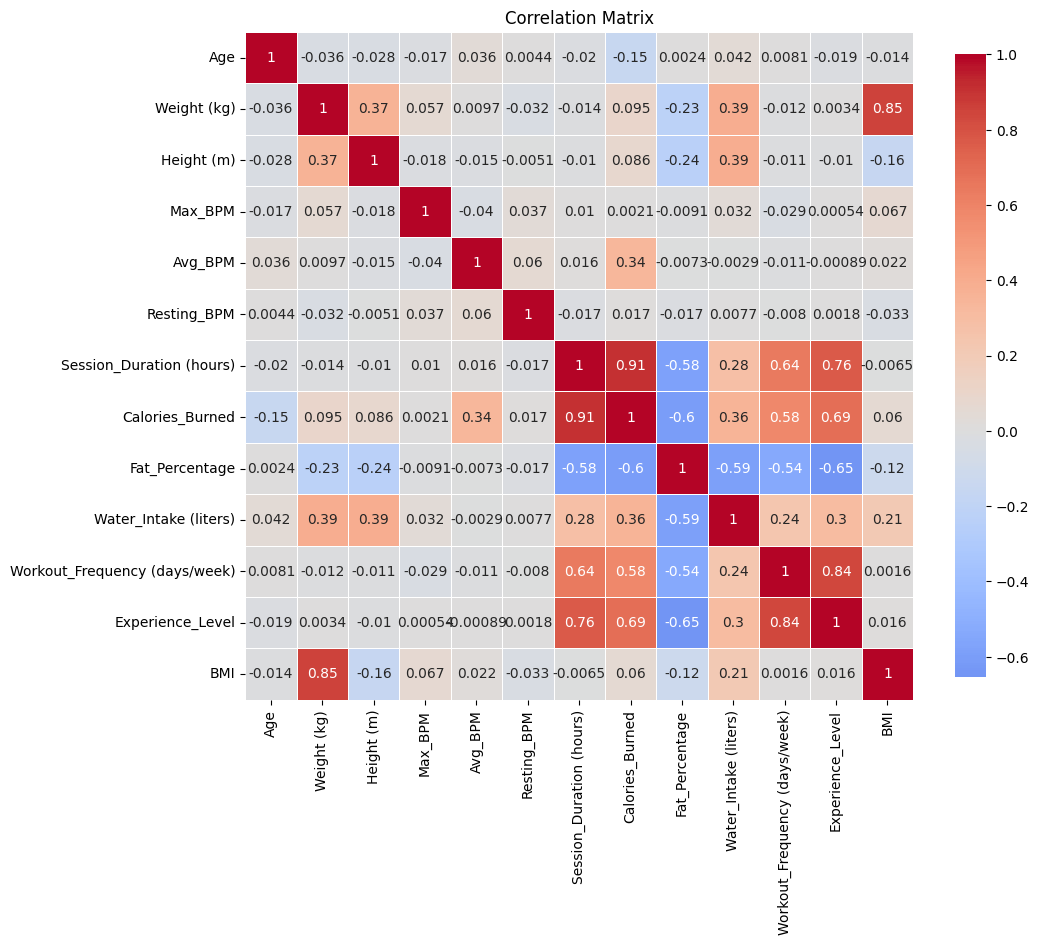

In [ ]:
numerical_cols = df.select_dtypes(include=[np.number]).columns
correlation_matrix = df[numerical_cols].corr()
plt.figure(figsize=(11, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, square=True, linewidths=0.5, cbar_kws={"shrink": .8})
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [ ]:
#Categorical Encoding
le_workout_type = LabelEncoder()
le_gender = LabelEncoder()

df['Workout_Type'] = le_workout_type.fit_transform(df['Workout_Type'])
df['Gender'] = le_gender.fit_transform(df['Gender'])


In [ ]:
#Splitting the features
X = df.drop('Workout_Type', axis=1)
y = df["Workout_Type"]

In [ ]:
#Splitting the dataset into train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

In [ ]:
#Best hyperparameters
hyperparameters = {
    'max_depth': [2, 4, 6, 8, 10],
    'criterion': ['gini', 'entropy'],
    'splitter' : ['best', 'random'],
    'min_samples_split': [2, 4, 6, 8, 10],
    'min_samples_leaf': [2, 4, 6, 8, 10]
}

decisionTreeClassifier = DecisionTreeClassifier(random_state= 1)
grid_search = GridSearchCV(decisionTreeClassifier, hyperparameters, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

Best parameters: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 2, 'splitter': 'random'}
Best score: 0.2866666666666666


In [ ]:
#Train and predict
decisionTreeClassifier = DecisionTreeClassifier(
    criterion = 'entropy',
    max_depth = 4,
    min_samples_leaf = 10,
    min_samples_split = 2,
    splitter = 'random',
    random_state= 1)

decisionTreeClassifier.fit(X_train, y_train)
y_pred = decisionTreeClassifier.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.18      0.42      0.25        40
           1       0.15      0.04      0.06        51
           2       0.33      0.05      0.09        55
           3       0.22      0.35      0.27        49

    accuracy                           0.20       195
   macro avg       0.22      0.22      0.17       195
weighted avg       0.23      0.20      0.16       195



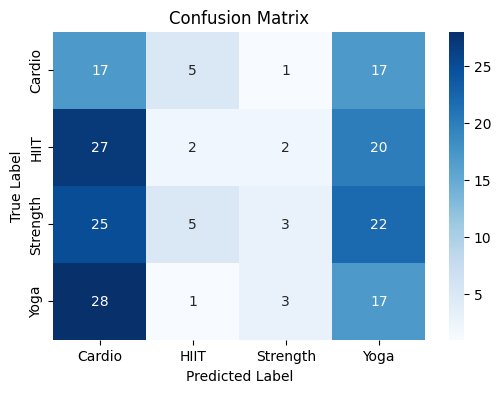

In [ ]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
category_name = le_workout_type.classes_
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=category_name, yticklabels=category_name)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
#Root node
root_index = decisionTreeClassifier.tree_.feature[0]
root_feature = X.columns[root_index]
print("Root node:", root_feature)


Root node: Resting_BPM


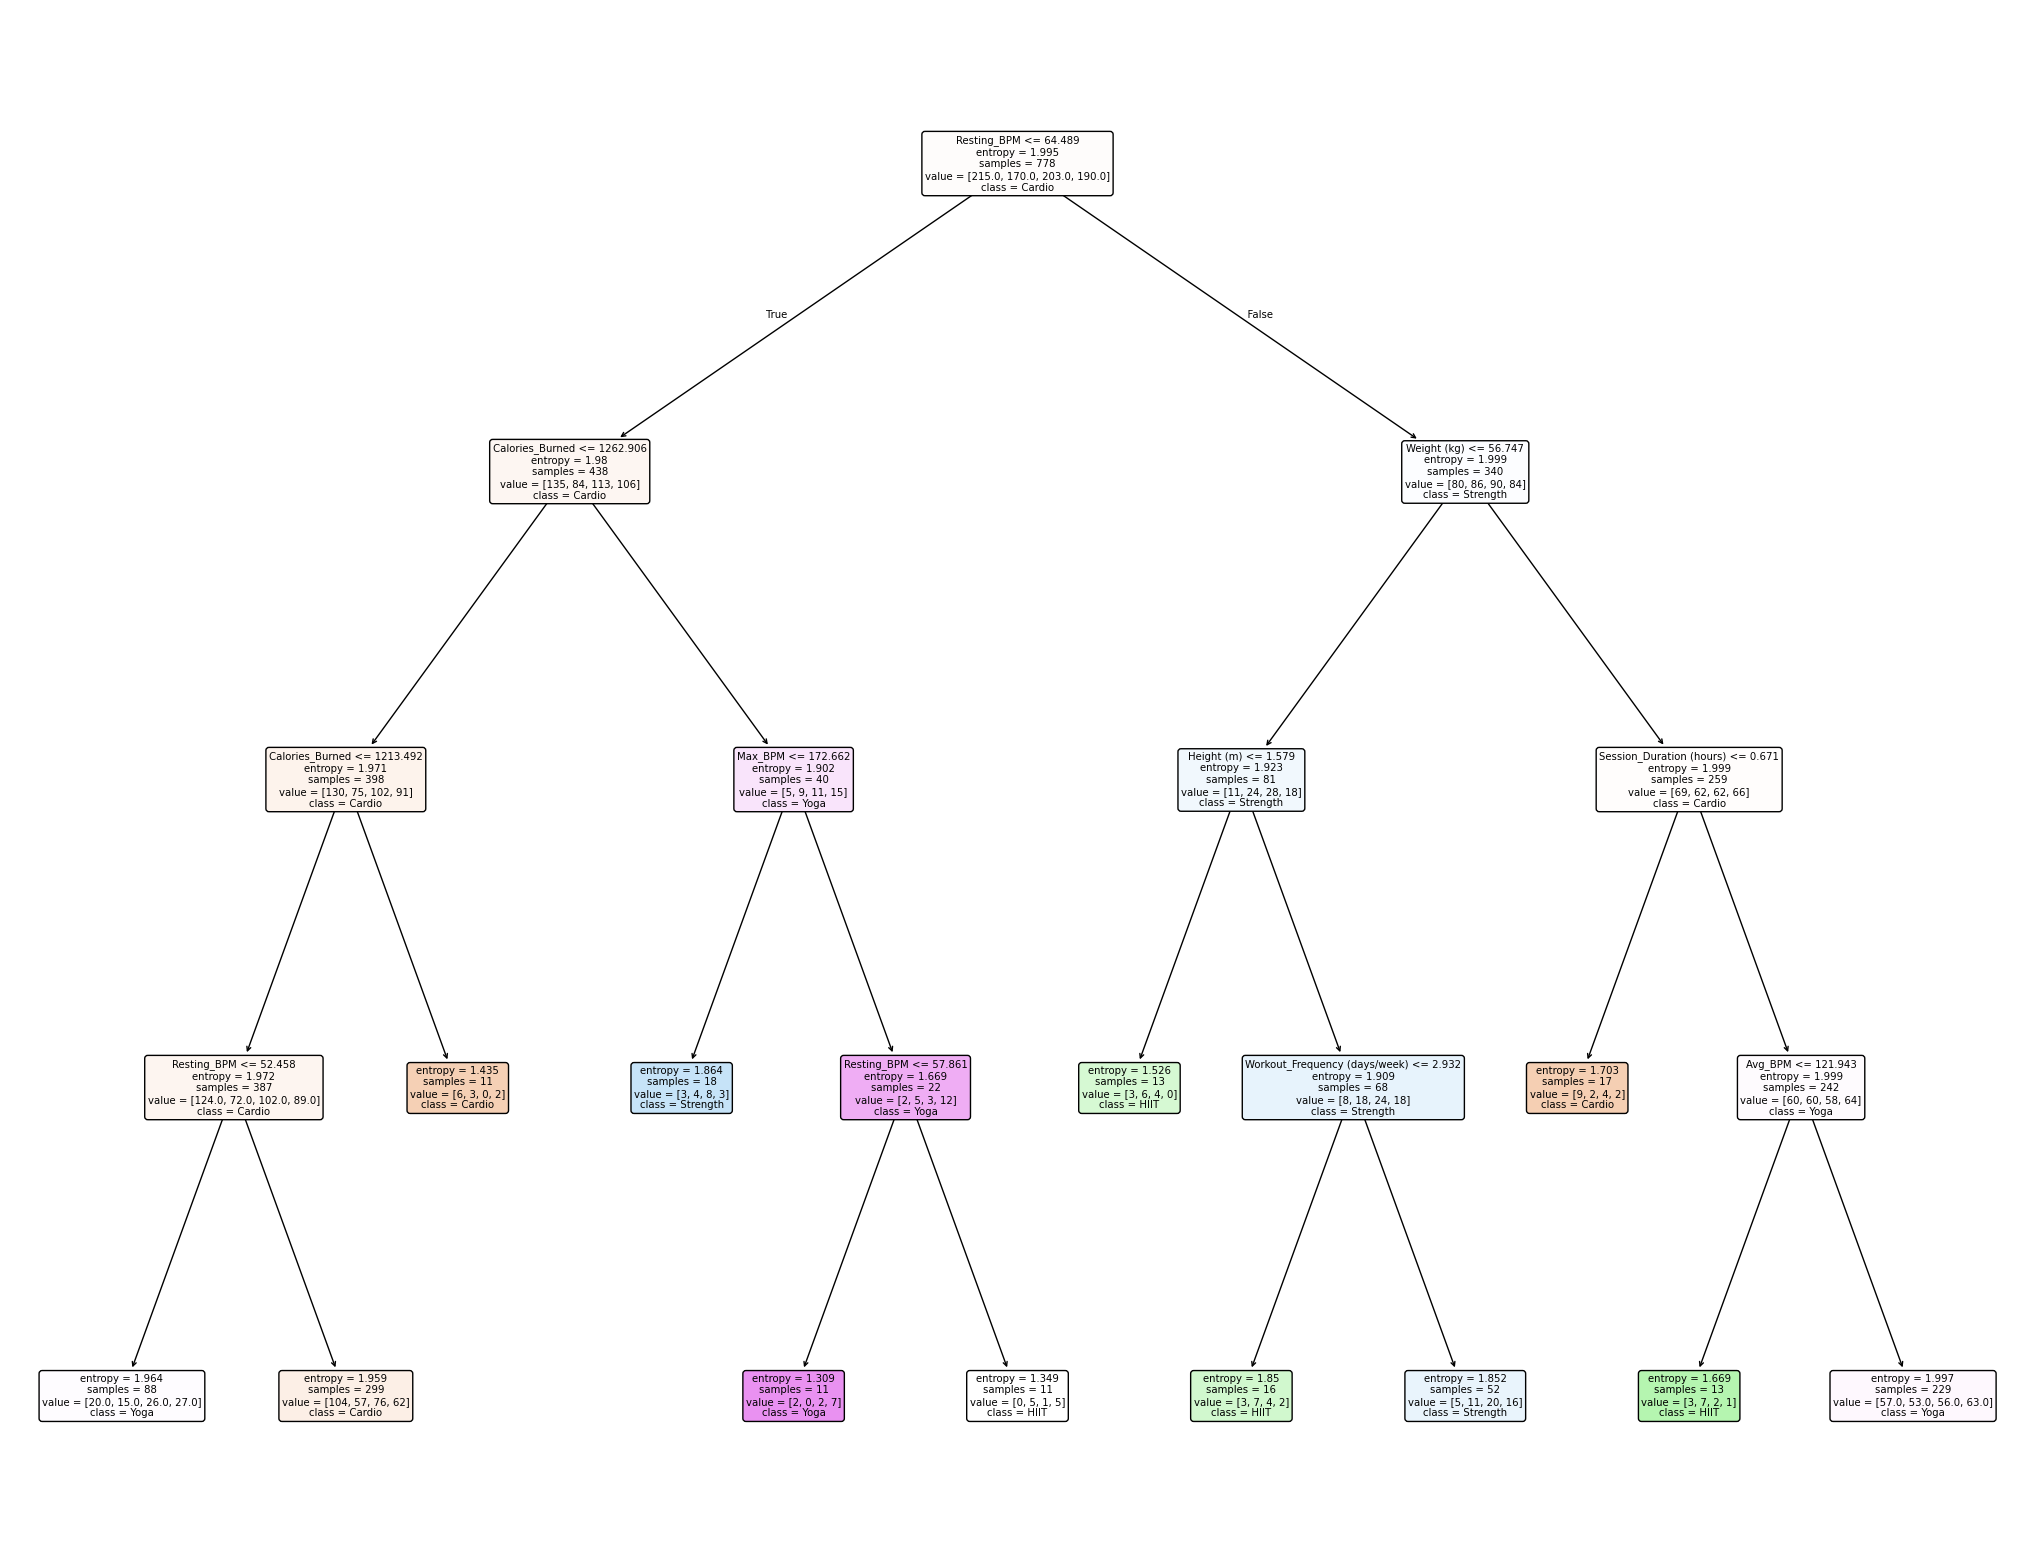

In [ ]:

plt.figure(figsize=(26,20))
tree.plot_tree(decisionTreeClassifier, feature_names=X_train.columns, class_names= category_name, filled=True, rounded=True)
plt.show()
